# Tree-Based Models Worked Example

This notebook follows the note and implements a worked regression example with decision trees, Random Forests, and XGBoost. It also defines the gradients and Hessians used in XGBoost for a squared error loss.

Sections:
1. Define loss gradients and Hessians.
2. Load and inspect a regression dataset.
3. Train XGBoost with a custom objective.
4. Train a Random Forest baseline.
5. Compare metrics and predictions.
6. Add visualization placeholders.


## 1. Define Loss Gradients and Hessians

We use squared error loss $l(y, \hat{y}) = \frac{1}{2}(y-\hat{y})^2$ so that:

$$
 g_i = \partial_{\hat{y}}\,l\left(y_i, \hat{y}_i^{(t-1)}\right) = \hat{y}_i^{(t-1)} - y_i,
 \qquad
 h_i = \partial_{\hat{y}}^2\,l\left(y_i, \hat{y}_i^{(t-1)}\right) = 1.
$$


In [1]:
import numpy as np


def squared_error_grad_hess(y_true, y_pred):
    """Return gradients and Hessians for squared error loss."""
    grad = y_pred - y_true
    hess = np.ones_like(grad)
    return grad, hess


# Quick sanity check
_y = np.array([3.0, -1.0, 2.0])
_yhat = np.array([2.5, -2.0, 2.5])
_g, _h = squared_error_grad_hess(_y, _yhat)
_g, _h

(array([-0.5, -1. ,  0.5]), array([1., 1., 1.]))

## 2. Load and Inspect Example Dataset

We use a synthetic regression dataset with nonlinear structure so trees have something meaningful to learn.

In [2]:
import pandas as pd
from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split

X, y = make_friedman1(n_samples=2500, n_features=12, noise=1.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)

pd.DataFrame({"y": y}).describe()

X shape: (2500, 12)
y shape: (2500,)


,y
count,2500.000000
mean,14.393745
std,4.942529
min,1.037777
25%,10.921240
50%,14.463940
75%,17.957497
max,28.945837


## 3. Train XGBoost with Custom Objective (Derivatives)

If `xgboost` is not installed, run the next cell. Otherwise you can skip it.

In [3]:
# Optional: install xgboost if needed
# %pip install xgboost

In [4]:
import warnings

try:
    import xgboost as xgb
except Exception as exc:
    xgb = None
    warnings.warn(f"XGBoost not available: {exc}")

xgb_preds = None
xgb_model = None

if xgb is not None:
    def squared_error_obj(preds, dtrain):
        labels = dtrain.get_label()
        grad = preds - labels
        hess = np.ones_like(grad)
        return grad, hess

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    params = {
        "max_depth": 4,
        "eta": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "seed": 42,
    }

    xgb_model = xgb.train(
        params,
        dtrain,
        num_boost_round=400,
        obj=squared_error_obj,
        evals=[(dtrain, "train"), (dtest, "test")],
        verbose_eval=False,
    )

    xgb_preds = xgb_model.predict(dtest)

xgb_preds is not None

True

## 4. Train Random Forest Baseline

In [5]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {}

models["tree"] = DecisionTreeRegressor(max_depth=4, random_state=42)
models["rf"] = RandomForestRegressor(n_estimators=300, random_state=42)

for name, model in models.items():
    model.fit(X_train, y_train)

rf_preds = models["rf"].predict(X_test)
rf_preds[:5]

array([22.50574691, 14.0371851 , 12.00493727, 14.78611747,  9.78761806])

## 5. Compare Metrics and Predictions

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

results = []

for name, model in models.items():
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    results.append({"model": name, "rmse": rmse, "mae": mae})

if xgb_preds is not None:
    rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
    mae = mean_absolute_error(y_test, xgb_preds)
    results.append({"model": "xgb", "rmse": rmse, "mae": mae})

metrics_df = pd.DataFrame(results).sort_values("rmse")
metrics_df

,model,rmse,mae
2,xgb,1.314820,1.011199
1,rf,1.993630,1.532700
0,tree,3.238146,2.596895


In [7]:
pred_table = pd.DataFrame({
    "y_true": y_test,
    "tree": models["tree"].predict(X_test),
    "rf": models["rf"].predict(X_test),
})

if xgb_preds is not None:
    pred_table["xgb"] = xgb_preds

pred_table.head(10)

,y_true,tree,rf,xgb
0,21.035704,21.067040,22.505747,21.777882
1,14.602489,15.409237,14.037185,14.482906
2,10.869669,10.668206,12.004937,10.875883
3,12.100431,15.409237,14.786117,13.798496
4,10.028106,8.364355,9.787618,9.193027
5,17.955777,18.279403,19.889728,19.433565
6,11.571020,14.426828,13.470280,12.239535
7,9.643056,11.199981,11.279239,11.027502
8,19.717590,13.019104,15.097742,16.537926
9,21.769112,21.067040,19.812924,21.648170


## 6. Add Code Snippets for Visualization Placeholders

These plots are useful for later screenshots. You can run them and save figures to add into the note.

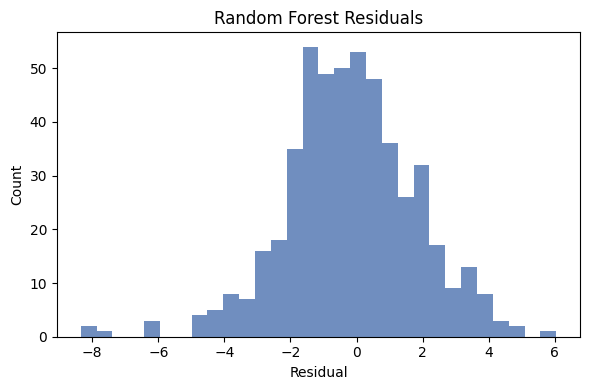

In [8]:
import matplotlib.pyplot as plt

# Residuals for the Random Forest
rf_residuals = y_test - models["rf"].predict(X_test)

plt.figure(figsize=(6, 4))
plt.hist(rf_residuals, bins=30, color="#4C72B0", alpha=0.8)
plt.title("Random Forest Residuals")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

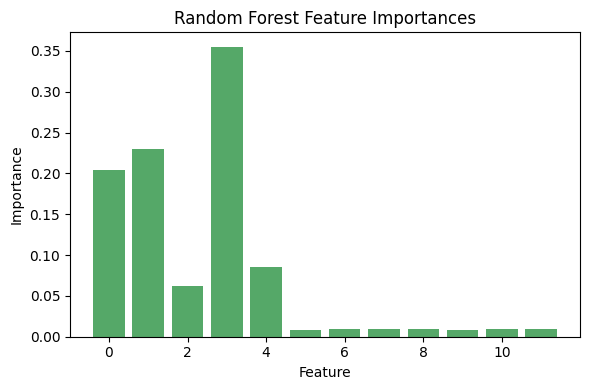

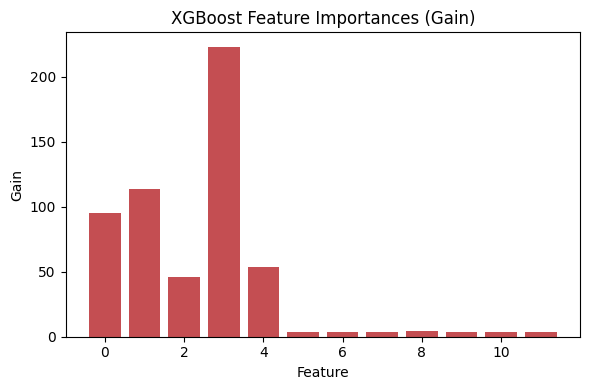

In [9]:
# Feature importance for Random Forest
rf_importances = models["rf"].feature_importances_

plt.figure(figsize=(6, 4))
plt.bar(range(len(rf_importances)), rf_importances, color="#55A868")
plt.title("Random Forest Feature Importances")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

# Feature importance for XGBoost (if available)
if xgb_model is not None:
    xgb_importance = xgb_model.get_score(importance_type="gain")
    xgb_keys = list(xgb_importance.keys())
    xgb_vals = [xgb_importance[k] for k in xgb_keys]

    plt.figure(figsize=(6, 4))
    plt.bar(range(len(xgb_vals)), xgb_vals, color="#C44E52")
    plt.title("XGBoost Feature Importances (Gain)")
    plt.xlabel("Feature")
    plt.ylabel("Gain")
    plt.tight_layout()
    plt.show()

## Summary and Next Steps

- Random Forest should reduce variance compared to a single tree.
- XGBoost should improve accuracy if its regularization is tuned well.
- Try increasing `max_depth`, adjusting `eta`, or adding more data to see bias/variance tradeoffs.

You can save the residual and feature importance plots to insert into the written note later.